In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

In [3]:
rng = np.random.default_rng(42)

In [4]:
def box_muller(n):
    u1 = rng.random(n)
    u2 = rng.random(n)

    u1 = np.maximum(u1, 1e-10)

    z1 = np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
    z2 = np.sqrt(-2 * np.log(u1)) * np.sin(2 * np.pi * u2)

    return np.column_stack((z1, z2))

In [5]:
def generate_gaussian(n, mu, sigma_x, sigma_y=None,
                      covariance_type="spherical", rho=0):

    z = box_muller(n)

    if sigma_y is None:
        sigma_y = sigma_x

    if covariance_type == "spherical":
        x1 = mu[0] + sigma_x * z[:, 0]
        x2 = mu[1] + sigma_x * z[:, 1]

    elif covariance_type == "diagonal":
        x1 = mu[0] + sigma_x * z[:, 0]
        x2 = mu[1] + sigma_y * z[:, 1]

    elif covariance_type == "full":
        x1 = mu[0] + sigma_x * z[:, 0]
        x2 = mu[1] + sigma_y * (
            rho * z[:, 0] +
            np.sqrt(1 - rho**2) * z[:, 1]
        )

    else:
        raise ValueError("Invalid covariance type")

    return np.column_stack((x1, x2))

In [6]:
n_samples = 1500

K = 3

pi = [0.2, 0.3, 0.5]


means_class1 = [
    [2, 2],
    [5, 5],
    [2, 6]
]

means_class2 = [
    [10, 2],
    [13, 5],
    [10, 6]
]

sigma_x = 1.0
sigma_y = 0.5

rho = 0.6

In [7]:
class LCG:
    def __init__(self, seed=42, a=1664525, b=1013904223, m=2**32):
        self.x = seed
        self.a = a
        self.b = b
        self.m = m

    def generate(self, n):
        values = []

        for i in range(n):
            self.x = (self.a * self.x + self.b) % self.m
            values.append(self.x / self.m)

        return np.array(values)


lcg = LCG(seed=42)

uniform_values = lcg.generate(n_samples)

print("Number of uniform values generated:", len(uniform_values))
print("\nGenerated uniform values:")
print(uniform_values)

print("\nMinimum value:", uniform_values.min())
print("Maximum value:", uniform_values.max())
print("All values in [0, 1):",
      np.all((uniform_values >= 0) & (uniform_values < 1)))

Number of uniform values generated: 1500

Generated uniform values:
[0.25234517 0.08812505 0.5772812  ... 0.61884237 0.83488758 0.47860366]

Minimum value: 0.0022425383795052767
Maximum value: 0.9993121819570661
All values in [0, 1): True


In [8]:
def select_components(uniform_values, weights):
    weights = np.asarray(weights, dtype=float)

    if len(weights) == 0:
        raise ValueError("Enter at least one probability")

    if np.any(~np.isfinite(weights)) or np.any(weights < 0):
        raise ValueError("Probabilities must be finite and non-negative")

    if not np.isclose(np.sum(weights), 1.0):
        raise ValueError("Probabilities must add up to 1")

    split_points = np.cumsum(weights)
    split_points[-1] = 1.0

    components = np.searchsorted(
        split_points, uniform_values, side="right"
    )

    return split_points, components


pi = [0.2, 0.3, 0.5]

split_points, components = select_components(uniform_values, pi)

print("Probabilities:", pi)
print("Split points:", split_points)
print()

lower = 0.0

for i in range(len(pi)):
    upper = split_points[i]
    count = np.sum(components == i)

    print(f"Mixture {i + 1}")
    print(f"Interval: {lower:.2f} <= u < {upper:.2f}")
    print(f"Number of values: {count}")
    print()

    lower = upper

print("First 20 values and their assigned mixtures:")

for i in range(min(20, len(uniform_values))):
    print(f"{uniform_values[i]:.4f} -> Mixture {components[i] + 1}")

Probabilities: [0.2, 0.3, 0.5]
Split points: [0.2 0.5 1. ]

Mixture 1
Interval: 0.00 <= u < 0.20
Number of values: 266

Mixture 2
Interval: 0.20 <= u < 0.50
Number of values: 465

Mixture 3
Interval: 0.50 <= u < 1.00
Number of values: 769

First 20 values and their assigned mixtures:
0.2523 -> Mixture 2
0.0881 -> Mixture 1
0.5773 -> Mixture 3
0.2226 -> Mixture 2
0.3757 -> Mixture 2
0.0257 -> Mixture 1
0.4473 -> Mixture 2
0.1185 -> Mixture 1
0.8738 -> Mixture 3
0.9946 -> Mixture 3
0.8532 -> Mixture 3
0.4997 -> Mixture 2
0.6420 -> Mixture 3
0.8615 -> Mixture 3
0.5965 -> Mixture 3
0.0908 -> Mixture 1
0.1402 -> Mixture 1
0.9501 -> Mixture 3
0.9246 -> Mixture 3
0.8895 -> Mixture 3


In [9]:
def check_split(uniform_values, split_points, components, weights):
    n = len(uniform_values)
    lower = 0.0
    total_count = 0

    print(
        f"{'Mixture':<12}"
        f"{'Interval':<18}"
        f"{'Count':<10}"
        f"{'Expected':<12}"
        f"{'Check'}"
    )
    print("-" * 65)

    for i, upper in enumerate(split_points):
        assigned_count = np.sum(components == i)

        interval_count = np.sum(
            (uniform_values >= lower) &
            (uniform_values < upper)
        )

        expected_count = n * weights[i]

        if assigned_count == interval_count:
            check = "Correct"
        else:
            check = "Error"

        interval = f"[{lower:.2f}, {upper:.2f})"

        print(
            f"{i + 1:<12}"
            f"{interval:<18}"
            f"{assigned_count:<10}"
            f"{expected_count:<12.1f}"
            f"{check}"
        )

        total_count += assigned_count
        lower = upper

    print("-" * 65)
    print("Total assigned:", total_count, "out of", n)


check_split(uniform_values, split_points, components, pi)

Mixture     Interval          Count     Expected    Check
-----------------------------------------------------------------
1           [0.00, 0.20)      266       300.0       Correct
2           [0.20, 0.50)      465       450.0       Correct
3           [0.50, 1.00)      769       750.0       Correct
-----------------------------------------------------------------
Total assigned: 1500 out of 1500


In [10]:
def generate_gmm(n, means, weights, covariance_type,
                 sigma_x, sigma_y=None, rho=0):

    if n <= 0:
        raise ValueError("Number of samples must be greater than 0")

    if len(means) != len(weights):
        raise ValueError("Number of means and probabilities must match")

    uniform_values = lcg.generate(n)

    split_points, components = select_components(
        uniform_values, weights
    )

    X = np.zeros((n, 2))

    for i in range(len(means)):
        count = np.sum(components == i)

        if count > 0:
            X[components == i] = generate_gaussian(
                count,
                means[i],
                sigma_x,
                sigma_y,
                covariance_type,
                rho
            )

    return X, components

In [11]:
X1, component1 = generate_gmm(
    n_samples,
    means_class1,
    pi,
    "full",
    sigma_x,
    sigma_y,
    rho
)

X2, component2 = generate_gmm(
    n_samples,
    means_class2,
    pi,
    "full",
    sigma_x,
    sigma_y,
    rho
)

np.set_printoptions(threshold=np.inf, precision=4)

print("\n========== CLASS 1 ==========")

for i in range(len(pi)):
    mixture_points = X1[component1 == i]

    print(f"\nMixture {i + 1}")
    print("Number of Gaussian points:", len(mixture_points))
    print("Gaussian data points:")
    print(mixture_points[:5])

print("\n========== CLASS 2 ==========")

for i in range(len(pi)):
    mixture_points = X2[component2 == i]

    print(f"\nMixture {i + 1}")
    print("Number of Gaussian points:", len(mixture_points))
    print("Gaussian data points:")
    print(mixture_points[:5])

print("\nClass 1 shape:", X1.shape)
print("Class 2 shape:", X2.shape)


========== CLASS 1 ==========

Mixture 1
Number of Gaussian points: 336
Gaussian data points:
[[2.5918 2.3386]
 [1.8049 1.4341]
 [2.4762 2.2547]
 [2.7812 2.1013]
 [3.4127 3.0846]]

Mixture 2
Number of Gaussian points: 419
Gaussian data points:
[[4.9573 4.9652]
 [4.7938 5.2651]
 [4.95   5.392 ]
 [3.8268 4.3667]
 [4.6448 4.9836]]

Mixture 3
Number of Gaussian points: 745
Gaussian data points:
[[3.5655e-03 5.2901e+00]
 [3.5169e+00 6.0689e+00]
 [2.2619e+00 5.7064e+00]
 [2.7120e+00 6.3237e+00]
 [1.5743e+00 5.9536e+00]]

========== CLASS 2 ==========

Mixture 1
Number of Gaussian points: 277
Gaussian data points:
[[ 9.4014  1.7695]
 [ 9.5434  2.2281]
 [11.3239  2.8093]
 [ 9.6085  1.6191]
 [12.1738  2.8385]]

Mixture 2
Number of Gaussian points: 450
Gaussian data points:
[[11.4773  4.3934]
 [13.2693  5.3261]
 [11.8202  4.66  ]
 [13.2258  5.1962]
 [13.5134  5.4848]]

Mixture 3
Number of Gaussian points: 773
Gaussian data points:
[[11.1298  6.3516]
 [10.5192  6.7103]
 [10.1727  6.8293]
 [10.32

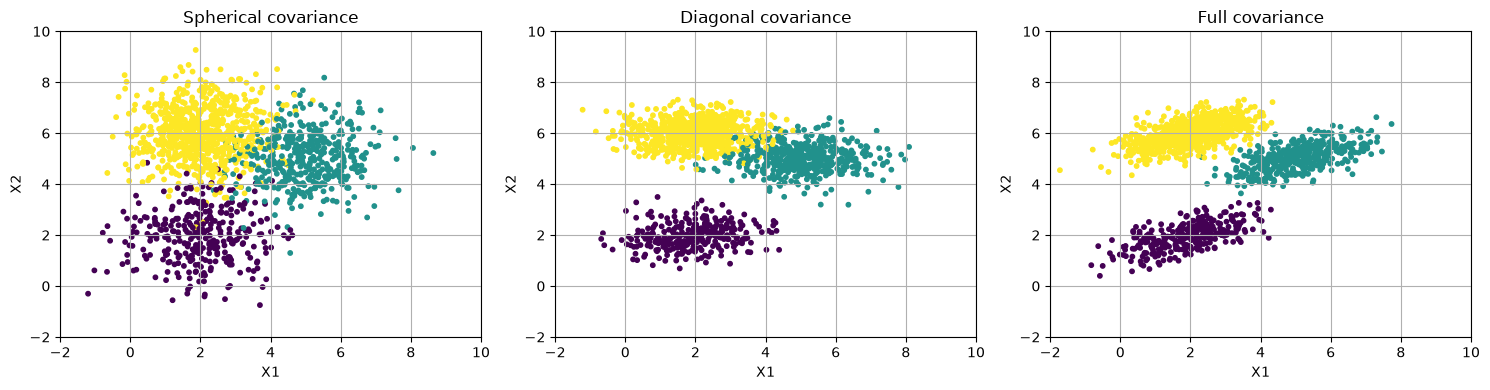

In [13]:
covariance_types = ["spherical", "diagonal", "full"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, cov_type in zip(axes, covariance_types):
    X, components = generate_gmm(
        1500, means_class1, pi, cov_type,
        sigma_x, sigma_y, rho
    )

    ax.scatter(X[:, 0], X[:, 1], c=components, s=10)
    ax.set_title(cov_type.capitalize() + " covariance")
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_xlim(-2, 10)
    ax.set_ylim(-2, 10)
    ax.grid(True)

plt.tight_layout()
plt.show()

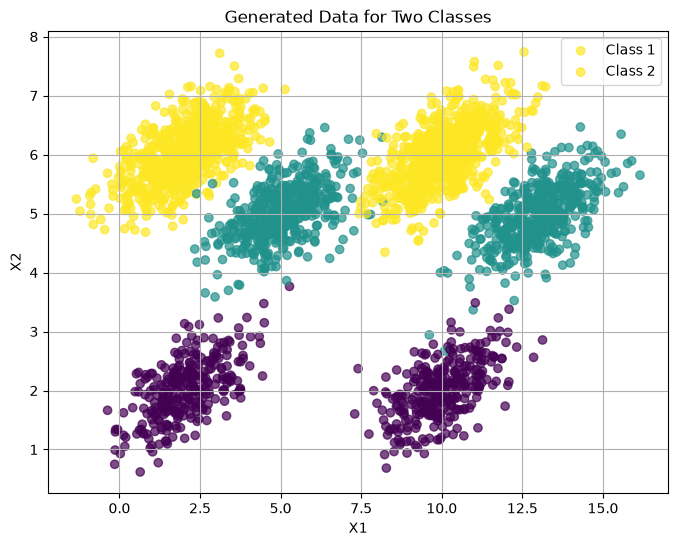

In [20]:
plt.figure(figsize=(8, 6))

plt.scatter(X1[:, 0], X1[:, 1], c=component1, label="Class 1", alpha=0.7)
plt.scatter(X2[:, 0], X2[:, 1], c=component2, label="Class 2", alpha=0.7)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Generated Data for Two Classes")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
def shuffle_indices(n):
    return rng.permutation(n)

In [22]:
def train_test_split(X):
    indices = shuffle_indices(len(X))
    split = int(0.8 * len(X))

    train = X[indices[:split]]
    test = X[indices[split:]]

    return train, test

X1_train, X1_test = train_test_split(X1)
X2_train, X2_test = train_test_split(X2)

print("Class 1 training:", len(X1_train))
print("Class 1 testing:", len(X1_test))
print("Class 2 training:", len(X2_train))
print("Class 2 testing:", len(X2_test))

Class 1 training: 1200
Class 1 testing: 300
Class 2 training: 1200
Class 2 testing: 300


In [23]:
def kmeans(X, K, max_iterations=100):
    indices = shuffle_indices(len(X))
    centroids = X[indices[:K]].copy()

    for _ in range(max_iterations):
        distances = np.zeros((len(X), K))

        for j in range(K):
            distances[:, j] = np.sum((X - centroids[j])**2, axis=1)

        labels = np.argmin(distances, axis=1)
        new_centroids = centroids.copy()

        for j in range(K):
            points = X[labels == j]

            if len(points) > 0:
                new_centroids[j] = np.mean(points, axis=0)

        if np.sum((new_centroids - centroids)**2) < 1e-8:
            centroids = new_centroids
            break

        centroids = new_centroids

    distances = np.zeros((len(X), K))

    for j in range(K):
        distances[:, j] = np.sum((X - centroids[j])**2, axis=1)

    labels = np.argmin(distances, axis=1)

    return centroids, labels

In [24]:
centroids1, labels1 = kmeans(X1_train, K)
centroids2, labels2 = kmeans(X2_train, K)

print("Class 1 centroids:")
print(centroids1)

print("\nClass 2 centroids:")
print(centroids2)

Class 1 centroids:
[[1.8759 5.9449]
 [5.0549 5.1158]
 [2.0056 2.0119]]

Class 2 centroids:
[[10.0024  5.9302]
 [13.0725  5.0876]
 [ 9.9763  2.0168]]


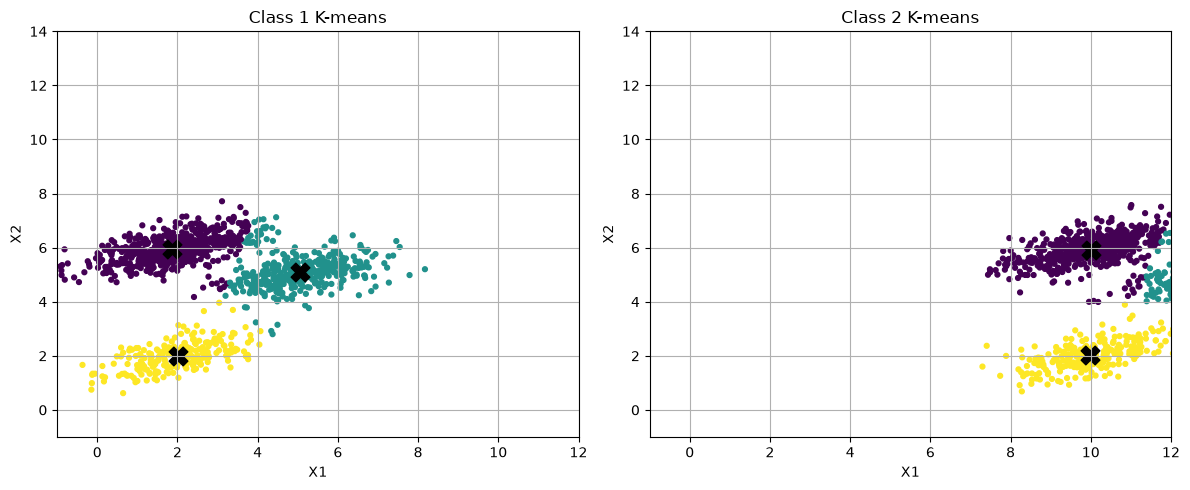

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X1_train[:, 0], X1_train[:, 1], c=labels1, s=12)
axes[0].scatter(centroids1[:, 0], centroids1[:, 1],
                marker="X", s=180, c="black")
axes[0].set_title("Class 1 K-means")

axes[1].scatter(X2_train[:, 0], X2_train[:, 1], c=labels2, s=12)
axes[1].scatter(centroids2[:, 0], centroids2[:, 1],
                marker="X", s=180, c="black")
axes[1].set_title("Class 2 K-means")

for ax in axes:
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_xlim(-1, 12)
    ax.set_ylim(-1, 14)
    ax.grid(True)

plt.tight_layout()
plt.show()

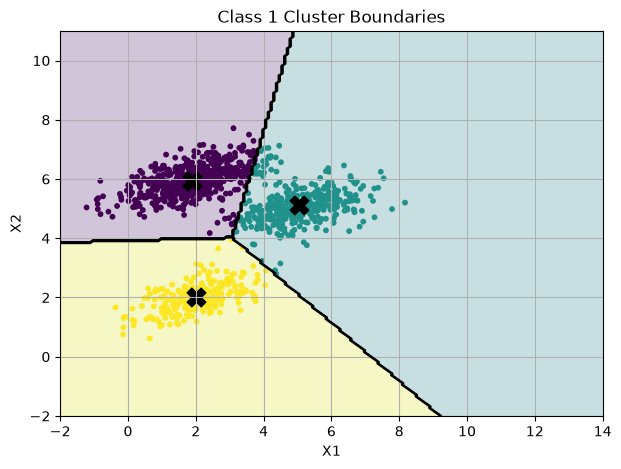

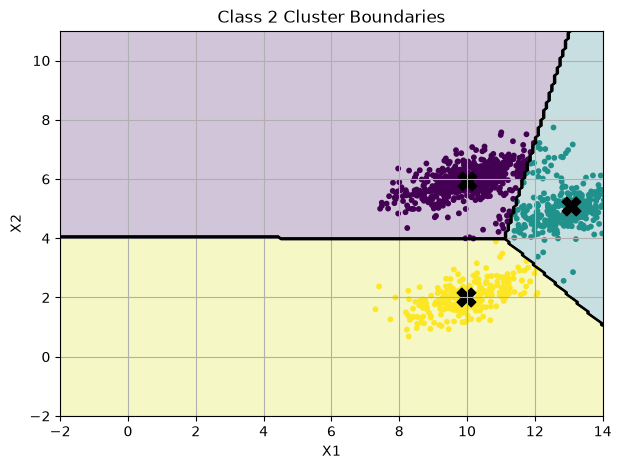

In [26]:

def plot_boundaries(X, centroids, labels, title):
    x_min, x_max = -2, 14
    y_min, y_max = -2, 11

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    grid = np.column_stack((xx.ravel(), yy.ravel()))
    distances = np.zeros((len(grid), len(centroids)))

    for j in range(len(centroids)):
        distances[:, j] = np.sum((grid - centroids[j])**2, axis=1)

    regions = np.argmin(distances, axis=1).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, regions, alpha=0.25)
    plt.contour(xx, yy, regions, colors="black", linewidths=1)

    plt.scatter(X[:, 0], X[:, 1], c=labels, s=10)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker="X", s=180, c="black")

    plt.title(title)
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.grid(True)
    plt.show()

plot_boundaries(X1_train, centroids1, labels1, "Class 1 Cluster Boundaries")
plot_boundaries(X2_train, centroids2, labels2, "Class 2 Cluster Boundaries")


In [27]:
def calculate_distortion(X, centroids):
    distances = np.zeros((len(X), len(centroids)))

    for j in range(len(centroids)):
        distances[:, j] = np.sum((X - centroids[j])**2, axis=1)

    return np.min(distances, axis=1)

def classify(X):
    distortion1 = calculate_distortion(X, centroids1)
    distortion2 = calculate_distortion(X, centroids2)

    predictions = np.where(distortion1 < distortion2, 0, 1)

    return predictions

In [28]:
X_test = np.vstack((X1_test, X2_test))

y_test = np.concatenate((
    np.zeros(len(X1_test), dtype=int),
    np.ones(len(X2_test), dtype=int)
))

predictions = classify(X_test)

accuracy = np.mean(predictions == y_test) * 100

print("Total test samples:", len(X_test))
print("Correct predictions:", np.sum(predictions == y_test))
print("Incorrect predictions:", np.sum(predictions != y_test))
print("Classification accuracy:", round(accuracy, 2), "%")

Total test samples: 600
Correct predictions: 598
Incorrect predictions: 2
Classification accuracy: 99.67 %


In [29]:
confusion_matrix = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(y_test, predictions):
    confusion_matrix[actual, predicted] += 1

print("Confusion Matrix:")
print(confusion_matrix)

Confusion Matrix:
[[298   2]
 [  0 300]]


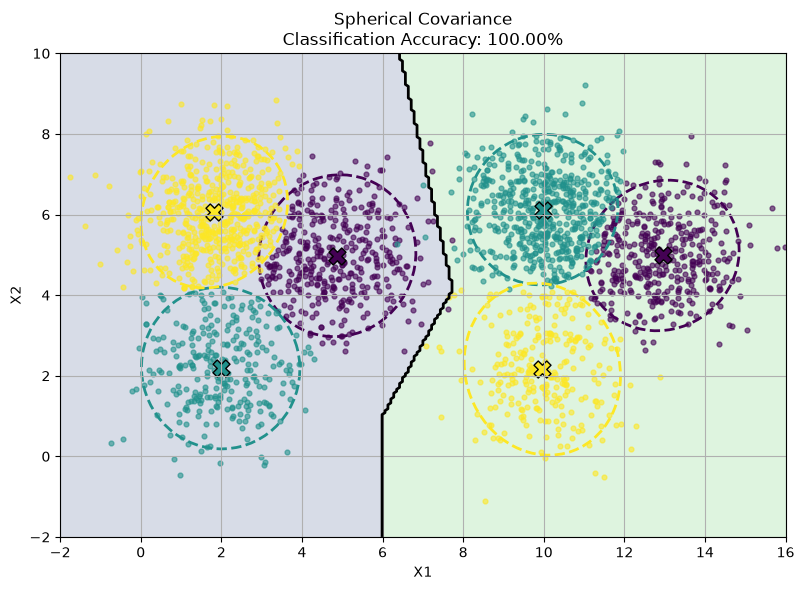

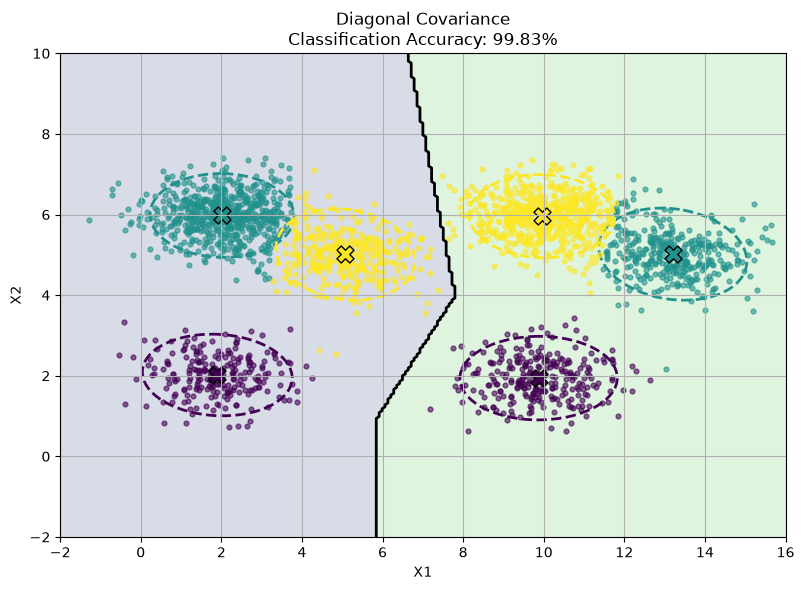

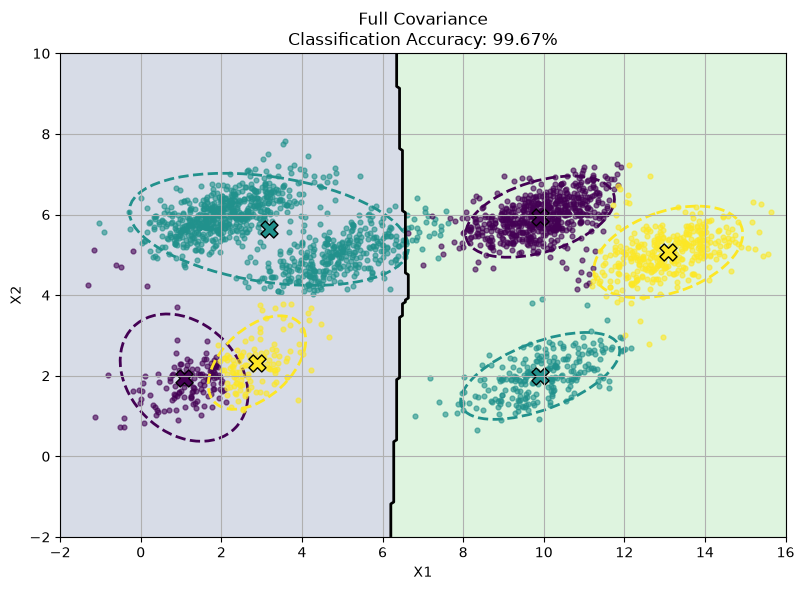

In [32]:
from matplotlib.patches import Ellipse

covariance_types = ["spherical", "diagonal", "full"]
colors = ["#440154", "#21918c", "#fde725"]

for cov_type in covariance_types:

    X1_cov, _ = generate_gmm(
        n_samples, means_class1, pi, cov_type,
        sigma_x, sigma_y, rho
    )

    X2_cov, _ = generate_gmm(
        n_samples, means_class2, pi, cov_type,
        sigma_x, sigma_y, rho
    )

    X1_train_cov, X1_test_cov = train_test_split(X1_cov)
    X2_train_cov, X2_test_cov = train_test_split(X2_cov)

    centroids1_cov, labels1_cov = kmeans(X1_train_cov, K)
    centroids2_cov, labels2_cov = kmeans(X2_train_cov, K)

    X_test_cov = np.vstack((X1_test_cov, X2_test_cov))

    y_test_cov = np.concatenate((
        np.zeros(len(X1_test_cov), dtype=int),
        np.ones(len(X2_test_cov), dtype=int)
    ))

    dist1 = calculate_distortion(X_test_cov, centroids1_cov)
    dist2 = calculate_distortion(X_test_cov, centroids2_cov)

    predictions_cov = np.where(dist1 < dist2, 0, 1)
    accuracy_cov = np.mean(predictions_cov == y_test_cov) * 100

    xx, yy = np.meshgrid(
        np.linspace(-2, 16, 250),
        np.linspace(-2, 10, 250)
    )

    grid = np.column_stack((xx.ravel(), yy.ravel()))

    grid_dist1 = calculate_distortion(grid, centroids1_cov)
    grid_dist2 = calculate_distortion(grid, centroids2_cov)

    regions = np.where(grid_dist1 < grid_dist2, 0, 1)
    regions = regions.reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(9, 6))

    ax.contourf(
        xx, yy, regions,
        levels=[-0.5, 0.5, 1.5],
        alpha=0.2
    )

    ax.contour(
        xx, yy, regions,
        levels=[0.5],
        colors="black",
        linewidths=2
    )

    for X_train, labels, centroids in [
        (X1_train_cov, labels1_cov, centroids1_cov),
        (X2_train_cov, labels2_cov, centroids2_cov)
    ]:

        for i in range(K):
            points = X_train[labels == i]

            ax.scatter(
                points[:, 0],
                points[:, 1],
                color=colors[i % len(colors)],
                s=12,
                alpha=0.6
            )

            ax.scatter(
                centroids[i, 0],
                centroids[i, 1],
                marker="X",
                s=150,
                color=colors[i % len(colors)],
                edgecolors="black"
            )

            if len(points) > 1:
                cov = np.cov(points, rowvar=False)

                values, vectors = np.linalg.eigh(cov)
                order = np.argsort(values)[::-1]

                values = values[order]
                vectors = vectors[:, order]

                angle = np.degrees(
                    np.arctan2(vectors[1, 0], vectors[0, 0])
                )

                width = 4 * np.sqrt(max(values[0], 0))
                height = 4 * np.sqrt(max(values[1], 0))

                ellipse = Ellipse(
                    centroids[i],
                    width=width,
                    height=height,
                    angle=angle,
                    fill=False,
                    edgecolor=colors[i % len(colors)],
                    linestyle="--",
                    linewidth=2
                )

                ax.add_patch(ellipse)

    ax.set_title(
        f"{cov_type.capitalize()} Covariance\n"
        f"Classification Accuracy: {accuracy_cov:.2f}%"
    )

    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_xlim(-2, 16)
    ax.set_ylim(-2, 10)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True)

    plt.tight_layout()
    plt.show()